# 1. Numerical integration

**Pin number**: 239

**Question 1.** 

Lowest order error term for the Trapezium rule is:

$ \frac{1}{12}f''(x_0)\Delta x^3 $

Order of error for the $N$-increment case is:

$ O(\Delta x^2) $


**Question 2.**

Lowest order error term for the Midpoint rule is: 

$ \frac{1}{24}f''(x_0)\Delta x^3 $

Order of error for the $N$-increment case is:

$ O(\Delta x^2) $


The following code imports two Python modules: <b><span style="color: blue;">math</span></b> which provides access to the mathematical functions, and <b><span style="color: blue;">matplotlib.pyplot</span></b> which is a collection of functions for creating figures and plotting.

In [114]:
# Execute this cell to import math and matplotlib.pyplot modules

import math
import matplotlib.pyplot as plt

In the following cell, we define parameters:

In [115]:
# Execute this cell to assign values to variables

PIN = 239
k = 3.0 - PIN/50
a = 2.0
b = 5.0
N = 256
Delta_x = (b-a)/N

%whos

Variable                         Type             Data/Info
-----------------------------------------------------------
Delta_x                          float            0.01171875
N                                int              256
NamespaceMagics                  MetaHasTraits    <class 'IPython.core.magi<...>mespace.NamespaceMagics'>
PIN                              int              239
a                                float            2.0
b                                float            5.0
coef_constant_lower              ndarray          2: 2 elems, type `float64`, 16 bytes
coef_constant_rule_lower         ndarray          2: 2 elems, type `float64`, 16 bytes
coef_constant_upper              ndarray          2: 2 elems, type `float64`, 16 bytes
coef_midpoint                    ndarray          2: 2 elems, type `float64`, 16 bytes
coef_simpson                     ndarray          2: 2 elems, type `float64`, 16 bytes
coef_trapezium                   ndarray          2: 2 elems, 

Now define the function $f(x)$:

In [28]:
# Execute this cell to define the function f(x)
def f(x):
    return (x**3+(3+k)*x**2)*math.log(x)

In [29]:
# You can use this cell to test whether your function f(x) is defined correctly.
# Try, e.g., calling the function value f(5.0) etc.

test = f(5.0)
print(test)

250.2675953835026


In the following cell, we calculate the true value of the integral of $f$ over the interval $[a,b]$:

In [30]:
# Execute this cell to calculate the exact value of the integral of f(x) over [a,b]

int_f=(b**4/4+(3+k)/3*b**3)*math.log(b)-b**4/16-(3+k)/9*b**3-((a**4/4+(3+k)/3*a**3)*math.log(a)-a**4/16-(3+k)/9*a**3)
print(int_f)

274.3376401502334


Now, let us define a vector $x_{values}$ to store the values of $x_i$ and the vector $f_{values}$ to store the values of $f(x_i)$

In [31]:
# Execute this cell to define x_0, x_1,... x_N and calculate f(x_0), f(x_1),..., f(x_N)

x_values = []
f_values = []
for i in range(0,N+1):
    x_values+=[a+i*Delta_x]
    f_values+=[f(x_values[i])]

The values $x_i$ and $f(x_i)$ can be tabulated by executing the following cell:

In [116]:
# Execute this cell to produce a table with values of x_i and f(x_i)

from tabulate import tabulate
tab=[]
for i in range(0,N+1,20):
    tab+=[[i,x_values[i],f_values[i]]]

#define header names
col_names = ["i","x_i", "f(x_i)"]
  
#display table
print(tabulate(tab, headers=col_names))

  i      x_i     f(x_i)
---  -------  ---------
  0  2          8.92774
 20  2.23438   13.8649
 40  2.46875   20.3172
 60  2.70312   28.5055
 80  2.9375    38.6571
100  3.17188   51.0046
120  3.40625   65.7863
140  3.64062   83.2451
160  3.875    103.629
180  4.10938  127.19
200  4.34375  154.185
220  4.57812  184.874
240  4.8125   219.52


Alternatively, the function $f(x)$ can also be plotted graphically.

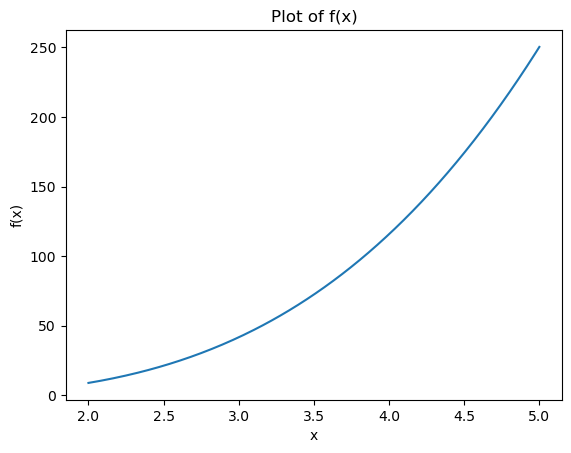

In [117]:
# Use this cell for plotting f(x) in the interval [a,b]

fig_plot_f = plt.figure()

# plotting the points  
plt.plot(x_values, f_values) 
    
# naming the x axis 
plt.xlabel('x') 
# naming the y axis 
plt.ylabel('f(x)') 
    
# giving a title to the graph 
plt.title('Plot of f(x)') 
    
# function to show the plot 
plt.show()

**Question 3.** Integrate numerically $f(x)$ over the interval $[a,b]$ by means of the Constant rule (lower and upper case), Trapezium rule, Midpoint rule and Simpson's rule and print your results.

In [118]:
constant_rule_lower = 0
for i in range (0,N):
    constant_rule_lower = constant_rule_lower + f_values[i]*Delta_x

constant_rule_upper = 0
for i in range (1,N+1):
    constant_rule_upper = constant_rule_upper + f_values[i]*Delta_x

trapezium_rule_value = Delta_x * (f(a) + f(b)) * 0.5
for i in range(1, N):
    trapezium_rule_value += f_values[i] * Delta_x

midpoint_rule_value = 0
for i in range(0, N):
    x_midpoint = a + (i + 0.5) * Delta_x
    midpoint_rule_value += f(x_midpoint)
midpoint_rule_value *= Delta_x

simpson_rule_value = (f(a) + f(b))
for i in range(1, N):
    if i % 2 == 0:
        simpson_rule_value += 2 * f_values[i]
    else:
        simpson_rule_value += 4 * f_values[i]
simpson_rule_value *= Delta_x/3

print('Constant rule lower:',constant_rule_lower)
print('Constant rule upper:',constant_rule_upper)
print('Trapezium rule value:',trapezium_rule_value)
print('Midpoint rule value:',midpoint_rule_value)
print('Simpsons rule value:',simpson_rule_value)



Constant rule lower: 272.9252938194228
Constant rule upper: 275.75349530025744
Trapezium rule value: 274.3393945598401
Midpoint rule value: 274.33676294547695
Simpsons rule value: 274.3376401507327


**Question 4.**  Write the functions constant_rule_lower(N), constant_rule_upper(N), trapezium_rule(N), midpoint_rule(N), simpsons_rule(N) that return the value of the numerical integral by means of the different numerical integration schemes.

In [119]:


def constant_rule_lower(N):
    constant_rule_lower = 0
    for i in range (0,N):
        constant_rule_lower = constant_rule_lower + f(a+i*(b-a)/N)*(b-a)/N
    return constant_rule_lower

def constant_rule_upper(N):
    constant_rule_upper = 0
    for i in range (1,N+1):
        constant_rule_upper += f(a+i*(b-a)/N)*(b-a)/N
    return constant_rule_upper

def trapezium_rule(N):
    Dx = (b-a)/N
    trapezium_value = Dx * (f(a) + f(b)) * 0.5
    for i in range(1, N):
        trapezium_value += f( a + i*Dx ) * Dx
    return trapezium_value

def midpoint_rule(N):
    Dx = (b-a)/N
    midpoint_value = 0
    for i in range(0, N):
        x_midpoint = a + (i + 0.5) * Dx
        midpoint_value += f(x_midpoint)
    midpoint_value *= Dx
    return midpoint_value

def simpson_rule(N):
    Dx = (b-a)/N
    simpson_value = (f(a) + f(b))
    for i in range(1, N):
        if i % 2 == 0:
            simpson_value += 2 * f(a + i*Dx)
        else:
            simpson_value += 4 * f(a + i*Dx)
    simpson_value *= Dx/3
    return simpson_value



print('Constant rule lower:',constant_rule_lower(256))
print('Constant rule upper:',constant_rule_upper(256))
print('Trapezium rule value:',trapezium_rule(256))
print('Midpoint rule value:',midpoint_rule(256))
print('Simpsons rule value:',simpson_rule(256))

Constant rule lower: 272.9252938194228
Constant rule upper: 275.75349530025744
Trapezium rule value: 274.3393945598401
Midpoint rule value: 274.33676294547695
Simpsons rule value: 274.3376401507327


**Question 5.** For each of the five integration rules (lower and upper Constant rules, Trapezium rule, Midpoint rule and Simpson's rule), calculate the following lists for $N=16, 32, 64, 128, 256 $ :

  1. the values of the numerical integrals
  2. the absolute values of errors between the numerical integrals and the exact integral value
  3. the natural logarithm of these absolute errors

In [120]:
data_N = [16, 32, 64, 128, 256]
ln_data_N = [math.log(ele) for ele in data_N]

constant_lower_N=[constant_rule_lower(ele) for ele in data_N]
error_constant_lower_N = [abs(ele - int_f) for ele in constant_lower_N]
ln_error_constant_lower_N = [math.log(ele) for ele in error_constant_lower_N]

constant_upper_N = [constant_rule_upper(ele) for ele in data_N]
error_constant_upper_N = [abs(ele - int_f) for ele in constant_upper_N]
ln_error_constant_upper_N = [math.log(ele) for ele in error_constant_upper_N]

trapezium_N = [trapezium_rule(ele) for ele in data_N]
error_trapezium_N = [abs(ele - int_f) for ele in trapezium_N]
ln_error_trapezium_N = [math.log(ele) for ele in error_trapezium_N]

midpoint_N = [midpoint_rule(ele) for ele in data_N]
error_midpoint_N = [abs(ele - int_f) for ele in midpoint_N]
ln_error_midpoint_N = [math.log(ele) for ele in error_midpoint_N]

simpson_N = [simpson_rule(ele) for ele in data_N]
error_simpson_N = [abs(ele - int_f) for ele in simpson_N]
ln_error_simpson_N = [math.log(ele) for ele in error_simpson_N]

**Question 6.** Create a table with seven columns showing $N$, $\ln(N)$ and $\ln|error|$ (natural logarithms of the absolute values of errors between the numerical values of the integral and the exact integral value) for five integration rules.

In [121]:
from tabulate import tabulate

tab = []
for i in range(0, 5):
    tab += [[data_N[i], ln_data_N[i], ln_error_constant_lower_N[i], ln_error_constant_upper_N[i], ln_error_trapezium_N[i], ln_error_midpoint_N[i], ln_error_simpson_N[i]]]

col_names = ["N","ln(N)","lnError_lower","lnError_upper","lnError_trapezium","lnError_midpoint","lnError_simpson"]

print(tabulate(tab, headers=col_names))

  N    ln(N)    lnError_lower    lnError_upper    lnError_trapezium    lnError_midpoint    lnError_simpson
---  -------  ---------------  ---------------  -------------------  ------------------  -----------------
 16  2.77259         3.09903          3.13874             -0.800464            -1.49362           -10.328
 32  3.46574         2.41596          2.43581             -2.18674             -2.87989           -13.1001
 64  4.15888         1.72781          1.73774             -3.57304             -4.26618           -15.8726
128  4.85203         1.03716          1.04212             -4.95933             -5.65248           -18.6452
256  5.54518         0.345252         0.347734            -6.34562             -7.03877           -21.4179


**Question 7.** Write the Python code to determine linear fit polynomials of $\ln|error|$ against $\ln(N)$ for five integration rules (lower and upper Constant rules, Trapezium rule, Midpoint rule and Simpson's rule).

In [122]:
import numpy as np

coef_constant_lower = np.polyfit(ln_data_N,ln_error_constant_lower_N,1)
fit_constant_lower = np.poly1d(coef_constant_lower)
print('The fit function for the constant rule lower is:', coef_constant_lower[0],'*x +',coef_constant_lower[1])

coef_constant_upper = np.polyfit(ln_data_N,ln_error_constant_upper_N,1)
fit_constant_upper = np.poly1d(coef_constant_upper)
print('The fit function for the constant rule upper is:', coef_constant_upper[0],'*x +',coef_constant_upper[1])

coef_trapezium = np.polyfit(ln_data_N,ln_error_trapezium_N,1)
fit_trapezium = np.poly1d(coef_trapezium)
print('The fit function for the trapezium rule is:', coef_trapezium[0],'*x +',coef_trapezium[1])

coef_midpoint = np.polyfit(ln_data_N,ln_error_midpoint_N,1)
fit_midpoint = np.poly1d(coef_midpoint)
print('The fit function for the midpoint rule is:', coef_midpoint[0],'*x +',coef_midpoint[1])

coef_simpson = np.polyfit(ln_data_N,ln_error_simpson_N,1)
fit_simpson = np.poly1d(coef_simpson)
print('The fit function for the simpson rule is:', coef_simpson[0],'*x +',coef_simpson[1])

The fit function for the constant rule lower is: -0.993492427524393 *x + 5.856861958930105
The fit function for the constant rule upper is: -1.0063809778239068 *x + 5.925849069062847
The fit function for the trapezium rule is: -1.9999941494535738 *x + 4.744702891094778
The fit function for the midpoint rule is: -1.9999897616215672 *x + 4.05153382293293
The fit function for the simpson rule is: -3.9998455411603393 *x + 0.7621152722141931


**Question 8.** Produce a figure showing the following:
1. scatter plots of $\ln|error|$ against $\ln(N)$
2. plots of linear fit polynomials
3. legend for the linear fit polynomials
4. appropriate axis labels and plot title
   
for all five numerical integration rules.

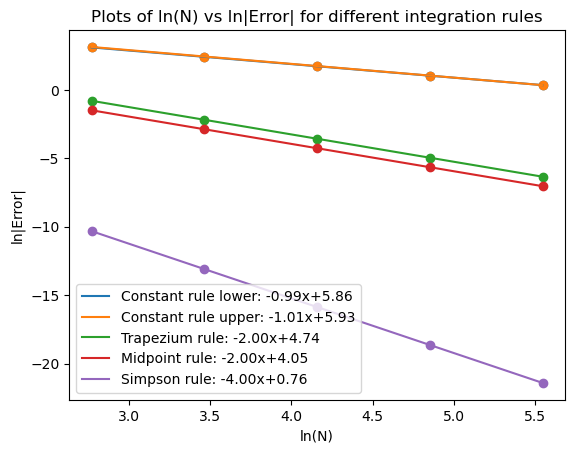

In [123]:
plt.scatter(ln_data_N, ln_error_constant_lower_N)
plt.plot(ln_data_N,fit_constant_lower(ln_data_N),label=f'Constant rule lower: {coef_constant_lower[0]:.2f}x+{coef_constant_lower[1]:.2f}')

plt.scatter(ln_data_N, ln_error_constant_upper_N)
plt.plot(ln_data_N,fit_constant_upper(ln_data_N),label=f'Constant rule upper: {coef_constant_upper[0]:.2f}x+{coef_constant_upper[1]:.2f}')

plt.scatter(ln_data_N, ln_error_trapezium_N)
plt.plot(ln_data_N,fit_trapezium(ln_data_N),label=f'Trapezium rule: {coef_trapezium[0]:.2f}x+{coef_trapezium[1]:.2f}')

plt.scatter(ln_data_N, ln_error_midpoint_N)
plt.plot(ln_data_N,fit_midpoint(ln_data_N),label=f'Midpoint rule: {coef_midpoint[0]:.2f}x+{coef_midpoint[1]:.2f}')

plt.scatter(ln_data_N, ln_error_simpson_N)
plt.plot(ln_data_N,fit_simpson(ln_data_N),label=f'Simpson rule: {coef_simpson[0]:.2f}x+{coef_simpson[1]:.2f}')

plt.xlabel("ln(N)")
plt.ylabel("ln|Error|")
plt.title("Plots of ln(N) vs ln|Error| for different integration rules")

leg = plt.legend(loc='lower left')
plt.show()
